# CMP-L045-0 Mathematics and Statistics for Data Science, Part 1: Applied Problem-Solving Activity

**Dataset:** World Bank, *World Development Indicators* (WDI), DataBank extract, 2015-2025 (last updated 08/10/2026)
**Analysis year:** 2024, the latest year in which every indicator is published (health expenditure: latest available, 2023)
**Source:** https://databank.worldbank.org/source/world-development-indicators (licence CC BY-4.0)

This notebook contains all code for the report. Sections follow the assessment brief:

1. Data loading and pre-processing (Task 1 support)
2. Task 2.1 Linear algebra: vectors
3. Task 2.2 Linear algebra: matrices
4. Task 2.3 Descriptive statistics and EDA
5. Task 2.4 Random variables and probability
6. Task 2.5 Interval estimates
7. Summary of outputs used in Task 3 (critical reflection)

Every figure is saved to `figures/` and every result table to `results/` so they can be placed in the report.

## 0. Setup: libraries and output folders

In [1]:
# Core numerical / statistical libraries
import os
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt

# Consistent, print-friendly plotting style for the report
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, ORANGE, GREY = "#1f5f99", "#d9822b", "#6b6b6b"

# Folders for exported graphs and result tables
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
np.set_printoptions(precision=4, suppress=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", stats.__name__)

numpy 2.5.3 | pandas 3.0.5 | scipy scipy.stats


In [2]:
import textwrap

def f(v, k=2):
    # number formatting used in all result tables (thousands separator, k decimals)
    return f"{v:,.{k}f}"

def save_table(table, name, title, values=None, fontsize=9):
    # Save a result table exactly as it appears in the report:
    #   results/<name>.csv  the formatted table (same labels and rounding as the report)
    #   results/<name>.png  the same table drawn in a plain academic layout
    #                       (a rule above, a rule under the header and a rule at the end)
    # 'values' (optional) is the unrounded table, saved as results/<name>_values.csv
    table.to_csv(f"results/{name}.csv", index=False)
    if values is not None:
        values.to_csv(f"results/{name}_values.csv")
    header = [textwrap.fill(str(c), 18) for c in table.columns]
    body = [[textwrap.fill(v, 42) if j == 0 else v for j, v in enumerate(r)] for r in table.astype(str).values.tolist()]
    n_cols = len(header)
    char_w = 0.068 * fontsize / 9                       # inches per character
    longest = lambda txt: max(len(line) for line in txt.split("\n"))
    widths = [max(longest(header[j]), max(longest(r[j]) for r in body)) * char_w + 0.3 for j in range(n_cols)]
    head_lines = max(h.count("\n") + 1 for h in header)
    line_h = 0.165
    head_h = line_h * head_lines + 0.08
    row_hs = [line_h * max(v.count("\n") + 1 for v in r) + 0.06 for r in body]
    W, H = sum(widths), 0.42 + head_h + sum(row_hs) + 0.1
    fig = plt.figure(figsize=(W, H))
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, W); ax.set_ylim(0, H); ax.axis("off")
    ax.text(W / 2, H - 0.16, title, ha="center", va="center", fontsize=fontsize, style="italic")
    top = H - 0.34
    ax.plot([0, W], [top, top], color="black", lw=0.9)
    ax.plot([0, W], [top - head_h, top - head_h], color="black", lw=0.5)
    bottom = top - head_h - sum(row_hs)
    ax.plot([0, W], [bottom, bottom], color="black", lw=0.9)
    row_mid = [top - head_h - sum(row_hs[:i]) - row_hs[i] / 2 for i in range(len(body))]
    x = 0
    for j in range(n_cols):
        left = j == 0
        xpos = x + 0.08 if left else x + widths[j] / 2
        ax.text(xpos, top - head_h / 2, header[j], ha="left" if left else "center", va="center",
                fontsize=fontsize, linespacing=1.1)
        for i, row in enumerate(body):
            ax.text(xpos, row_mid[i], row[j], ha="left" if left else "center",
                    va="center", fontsize=fontsize, linespacing=1.1)
        x += widths[j]
    fig.savefig(f"results/{name}.png", dpi=200, bbox_inches="tight", pad_inches=0.05, facecolor="white")
    plt.close(fig)
    return table

## 1. Data loading and pre-processing

The raw DataBank CSV is in *wide* format: one row per (country, series) and one column per year.
Raw issues handled here:

* missing values are coded as the string `..`;
* five footer lines (blank rows, "Data from database…", "Last Updated…") are appended to the file;
* 266 "countries" include **48 regional / income / lending-group aggregates** (e.g. *World*, *High income*) that must be removed, otherwise countries would be double-counted;
* the data must be reshaped from wide to a long **country-year panel**.

In [3]:
# Load the raw World Bank DataBank extract exactly as downloaded
raw = pd.read_csv("data/raw/WDI_Data_2015_2025.csv")
print("Raw shape:", raw.shape)

# Drop the footer rows (they have no series code)
raw = raw.dropna(subset=["Series Code"])
print("After removing footer rows:", raw.shape)
print("Entities:", raw["Country Code"].nunique(), "| Series:", raw["Series Code"].nunique())
raw.head(3)

Raw shape: (1601, 15)
After removing footer rows: (1596, 15)
Entities: 266 | Series: 6


,Country Name,Country Code,Series Name,Series Code,2015 [YR2015],2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,565.569730408751,522.082215583898,525.469770891619,491.337221382603,496.6025042585,510.787063366811,356.496214115892,357.261152798144,413.757894705303,416.871146273728,..
1,Afghanistan,AFG,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,62.27,62.646,62.406,62.443,62.941,61.454,60.417,65.617,66.035,66.289,..
2,Afghanistan,AFG,Current health expenditure (% of GDP),SH.XPD.CHEX.GD.ZS,10.10534763,11.81859016,12.62081718,14.20841885,14.83131981,15.53361416,21.50844383,23.0881691,14.9857626,..,..


In [4]:
# World Bank aggregate codes (regions, income groups, lending groups, World), not individual countries
AGGREGATES = {
    "AFE","AFW","ARB","CEB","CSS","EAP","EAR","EAS","ECA","ECS","EMU","EUU","FCS","HIC","HPC",
    "IBD","IBT","IDA","IDB","IDX","INX","LAC","LCN","LDC","LIC","LMC","LMY","LTE","MEA","MIC",
    "MNA","NAC","OED","OSS","PRE","PSS","PST","SAS","SSA","SSF","SST","TEA","TEC","TLA","TMN",
    "TSA","TSS","UMC","WLD",
}
present = AGGREGATES & set(raw["Country Code"])
print(f"Aggregates found and removed: {len(present)}")
raw = raw[~raw["Country Code"].isin(AGGREGATES)]
print("Countries kept:", raw["Country Code"].nunique())

Aggregates found and removed: 48
Countries kept: 218


In [5]:
# Short, analysis-friendly names for the 6 series
RENAME = {
    "NY.GDP.PCAP.CD":    "gdp_pc",       # GDP per capita, current US$
    "SP.DYN.LE00.IN":    "life_exp",     # life expectancy at birth, total (years)
    "SH.XPD.CHEX.GD.ZS": "health_exp",   # current health expenditure, % of GDP
    "SP.URB.TOTL.IN.ZS": "urban",        # urban population, % of total
    "IT.NET.USER.ZS":    "internet",     # individuals using the Internet, % of population
    "SP.DYN.TFRT.IN":    "fertility",    # births per woman
}

# Wide (years as columns) -> long -> panel (one row per country-year, one column per variable)
year_cols = [c for c in raw.columns if "[YR" in c]
long = raw.melt(id_vars=["Country Name", "Country Code", "Series Code"],
                value_vars=year_cols, var_name="year", value_name="value")
long["year"] = long["year"].str[:4].astype(int)
long["value"] = pd.to_numeric(long["value"].replace("..", np.nan), errors="coerce")  # '..' -> NaN
long["var"] = long["Series Code"].map(RENAME)

panel = (long.set_index(["Country Name", "Country Code", "year", "var"])["value"]
             .unstack("var")                 # one column per variable, missing values kept as NaN
             .reset_index()
             .rename(columns={"Country Name": "country", "Country Code": "code"}))
panel = panel[["country", "code", "year"] + list(RENAME.values())]
panel.columns.name = None
print("Panel shape (rows = country-years):", panel.shape)
panel.to_csv("data/wdi_panel_clean.csv", index=False)
panel.head()

Panel shape (rows = country-years): (2398, 9)


,country,code,year,gdp_pc,life_exp,health_exp,urban,internet,fertility
0,Afghanistan,AFG,2015,565.5697,62.2700,10.1053,24.4649,8.2600,5.6520
1,Afghanistan,AFG,2016,522.0822,62.6460,11.8186,24.6588,11.0000,5.5420
2,Afghanistan,AFG,2017,525.4698,62.4060,12.6208,24.8353,13.5000,5.4330
3,Afghanistan,AFG,2018,491.3372,62.4430,14.2084,24.9992,16.8000,5.3270
4,Afghanistan,AFG,2019,496.6025,62.9410,14.8313,25.1437,17.6000,5.2380


In [6]:
# Missing-value audit per variable (share of the 2,398 country-years: 218 economies x 11 years)
VARS = list(RENAME.values())
missing = (panel[VARS].isna().mean() * 100).round(2).to_frame("% missing")
missing["non-missing n"] = panel[VARS].notna().sum()
# Latest year with data for each indicator: shows why 2024 is the analysis year
missing["latest year"] = [str(int(panel.loc[panel[v].notna(), "year"].max())) for v in VARS]
missing[f"% present in 2024"] = [(panel.loc[panel["year"] == 2024, v].notna().mean() * 100).round(1) for v in VARS]
NAMES = {"gdp_pc": "GDP per capita (US$)", "life_exp": "Life expectancy (years)",
         "health_exp": "Health expenditure (% of GDP)", "urban": "Urban population (%)",
         "internet": "Internet users (%)", "fertility": "Fertility rate (births per woman)"}
tab1 = pd.DataFrame({
    "Variable": [NAMES[v] for v in VARS],
    "Missing (%)": [f(x, 1) for x in missing["% missing"]],
    "Observed values": [f"{int(x):,}" for x in missing["non-missing n"]],
    "Latest year": missing["latest year"].tolist(),
    "Available in 2024 (%)": [f(x, 1) for x in missing["% present in 2024"]],
})
save_table(tab1, "tab0_missing", "Missing values and latest available year in the 2,398-row panel", values=missing)

,Variable,Missing (%),Observed values,Latest year,Available in 2024 (%)
0,GDP per capita (US$),4.7,"2,286",2025,92.2
1,Life expectancy (years),9.1,"2,180",2024,100.0
2,Health expenditure (% of GDP),26.6,"1,761",2024,10.1
3,Urban population (%),0.0,"2,398",2025,100.0
4,Internet users (%),21.0,"1,894",2025,83.5
5,Fertility rate (births per woman),9.1,"2,180",2024,100.0


In [7]:
# Cross-section used for most analyses: the LATEST year in which every indicator is published.
# 2025 has no life expectancy or fertility yet, so the analysis year is 2024.
LATEST = 2024
df22 = panel[panel["year"] == LATEST].copy()      # (variable name kept short: 'the latest cross-section')

# Health expenditure is only published to 2023: use each country's latest available value (and record its year)
hx = (panel[(panel["year"] <= LATEST) & panel["health_exp"].notna()]
      .sort_values("year").groupby("code")[["health_exp", "year"]].last()
      .rename(columns={"year": "health_year"}))
df22 = df22.drop(columns="health_exp").merge(hx, left_on="code", right_index=True, how="left")
print("Year of the health-expenditure value used:\n", df22["health_year"].dropna().astype(int).value_counts().sort_index().to_string())

# A log transform of GDP per capita is added because income is strongly right-skewed (shown in Task 2.3).
df22["log_gdp"] = np.log(df22["gdp_pc"])

# Self-defined criterion (brief: 'selecting attributes to satisfy self-defined criteria'):
# 'Higher-income' = GDP per capita at or above the 2024 median of all countries with data.
gdp_median = df22["gdp_pc"].median()
df22["income_grp"] = np.where(df22["gdp_pc"] >= gdp_median, "Higher-income", "Lower-income")
df22.loc[df22["gdp_pc"].isna(), "income_grp"] = np.nan
print(f"{LATEST} countries: {len(df22)} | median GDP per capita = US$ {gdp_median:,.0f}")
print(df22["income_grp"].value_counts())

Year of the health-expenditure value used:
 health_year
2021      1
2023    171
2024     22
2024 countries: 218 | median GDP per capita = US$ 7,754
income_grp
Higher-income    101
Lower-income     100
Name: count, dtype: int64


## 2. Task 2.1: Linear algebra: vectors

Each country is one component, so a variable measured across *n* countries is a vector in $\mathbb{R}^n$.
Using life expectancy in **2019** (before COVID-19) and **2024** (latest year), $\mathbf a,\mathbf b$:

* Dot product $\mathbf a\cdot\mathbf b=\sum_i a_i b_i$
* Euclidean norm $\lVert\mathbf a\rVert=\sqrt{\mathbf a\cdot\mathbf a}$
* Cosine similarity $\cos\theta=\dfrac{\mathbf a\cdot\mathbf b}{\lVert\mathbf a\rVert\,\lVert\mathbf b\rVert}$
* Difference vector $\mathbf d=\mathbf b-\mathbf a$ (change per country) and its norm
* Scalar projection coefficient $c=\dfrac{\mathbf a\cdot\mathbf b}{\mathbf a\cdot\mathbf a}$, the multiple of $\mathbf a$ closest to $\mathbf b$

Raw vectors all lie in the positive orthant, so cosine similarity is inflated by the common level of the data.
After **centering** ($\tilde{\mathbf a}=\mathbf a-\bar a\mathbf 1$) the cosine equals Pearson's correlation $r$, which measures co-movement.

In [8]:
# Vectors: life expectancy in 2019 (pre-COVID) and 2024 (latest) for countries with both values
v = panel.pivot(index="code", columns="year", values="life_exp")[[2019, LATEST]].dropna()
a = v[2019].to_numpy()
b = v[LATEST].to_numpy()
n = len(a)

dot_ab  = a @ b                       # dot product
norm_a  = np.sqrt(a @ a)              # ||a|| from the definition
norm_b  = np.linalg.norm(b)           # ||b|| with numpy (check)
cos_ab  = dot_ab / (norm_a * norm_b)  # cosine similarity
angle   = np.degrees(np.arccos(cos_ab))
c_proj  = dot_ab / (a @ a)            # projection coefficient: b ~ c * a

d       = b - a                       # vector subtraction: change 2019 -> 2024 per country
norm_d  = np.linalg.norm(d)
rms_d   = norm_d / np.sqrt(n)         # ||d|| / sqrt(n) = root-mean-square change

ac, bc  = a - a.mean(), b - b.mean()  # centred vectors
cos_c   = (ac @ bc) / (np.linalg.norm(ac) * np.linalg.norm(bc))

print(f"n = {n}")
print(f"a.b = {dot_ab:,.2f}; ||a|| = {norm_a:,.3f}; ||b|| = {norm_b:,.3f}")
print(f"cosine(a, b) = {cos_ab:.5f}  (angle = {angle:.2f} deg); projection coefficient c = {c_proj:.4f}")
print(f"d = b - a: mean = {d.mean():.3f} y, ||d|| = {norm_d:.3f}, RMS = {rms_d:.3f}, "
      f"min = {d.min():.2f} ({v.index[d.argmin()]}), max = {d.max():.2f} ({v.index[d.argmax()]})")
print(f"countries above 2019 level: {(d > 0).sum()} of {n} ({(d > 0).mean():.1%})")
print(f"cosine of centred vectors = {cos_c:.4f}; Pearson r check = {np.corrcoef(a, b)[0,1]:.4f}")

n = 218
a.b = 1,188,921.58; ||a|| = 1,083.977; ||b|| = 1,097.222
cosine(a, b) = 0.99963  (angle = 1.56 deg); projection coefficient c = 1.0118
d = b - a: mean = 0.990 y, ||d|| = 32.551, RMS = 2.205, min = -6.60 (PSE), max = 26.14 (CAF)
countries above 2019 level: 197 of 218 (90.4%)
cosine of centred vectors = 0.9723; Pearson r check = 0.9723


In [9]:
# Second pair: log GDP per capita vs life expectancy (centred cosine = correlation),
# plus a check of the Cauchy-Schwarz inequality |x.y| <= ||x|| ||y||
w = df22[["log_gdp", "life_exp"]].dropna()
x = w["log_gdp"].to_numpy() - w["log_gdp"].mean()
y = w["life_exp"].to_numpy() - w["life_exp"].mean()
cos_xy = (x @ y) / (np.linalg.norm(x) * np.linalg.norm(y))
print(f"n = {len(w)}; centred cosine(log GDP, life expectancy) = {cos_xy:.4f}")
print("Cauchy-Schwarz holds:", abs(x @ y) <= np.linalg.norm(x) * np.linalg.norm(y))

vec_tab = pd.DataFrame({
    "Value": [n, dot_ab, norm_a, norm_b, cos_ab, angle, c_proj, d.mean(), norm_d, rms_d, cos_c, len(w), cos_xy]
}, index=["n (countries)", "Dot product a.b", "||a|| (LE 2019)", f"||b|| (LE {LATEST})", "Cosine(a, b) raw",
          "Angle (degrees)", "Projection coefficient c", "Mean change d (years)", "||d|| = ||b - a||",
          "RMS change ||d||/sqrt(n)", "Cosine(a, b) centred", f"n (log GDP, LE {LATEST})", "Cosine(logGDP, LE) centred"])
tab2 = pd.DataFrame([
    ["Countries (n)", f"{n}"], ["Dot product a·b", f(dot_ab, 0)],
    ["‖a‖, life expectancy 2019", f(norm_a, 1)], [f"‖b‖, life expectancy {LATEST}", f(norm_b, 1)],
    ["Cosine similarity (raw)", f(cos_ab, 5)], ["Angle between a and b (degrees)", f(angle, 2)],
    ["Projection coefficient c", f(c_proj, 3)], ["Mean change, d = b - a (years)", f(d.mean(), 2)],
    ["‖d‖", f(norm_d, 2)], ["RMS change, ‖d‖/√n (years)", f(rms_d, 2)],
    ["Cosine similarity (centred)", f(cos_c, 3)],
    [f"Countries with GDP and life expectancy, {LATEST}", f"{len(w)}"],
    ["Centred cosine, ln GDP and life expectancy", f(cos_xy, 3)],
], columns=["Quantity", "Value"])
save_table(tab2, "tab1_vectors", "Vector operations (notebook output)", values=vec_tab)

n = 201; centred cosine(log GDP, life expectancy) = 0.8622
Cauchy-Schwarz holds: True


,Quantity,Value
0,Countries (n),218
1,Dot product a·b,"1,188,922"
2,"‖a‖, life expectancy 2019","1,084.0"
3,"‖b‖, life expectancy 2024","1,097.2"
4,Cosine similarity (raw),0.99963
5,Angle between a and b (degrees),1.56
6,Projection coefficient c,1.012
7,"Mean change, d = b - a (years)",0.99
8,‖d‖,32.55
9,"RMS change, ‖d‖/√n (years)",2.20


## 3. Task 2.2: Linear algebra: matrices

**Data matrix.** $X\in\mathbb{R}^{n\times p}$ with one row per country (2024, complete cases; health expenditure = latest available) and $p=6$ columns:
log GDP per capita, life expectancy, health expenditure, urbanisation, internet use, fertility.

**Pre-processing with matrix operations.**
Centering matrix $H=I_n-\tfrac1n\mathbf 1\mathbf 1^\top$ gives $X_c=HX$ (column means become 0).
Scaling matrix $D=\operatorname{diag}(s_1,\dots,s_p)$ gives the standardised matrix $Z=X_cD^{-1}$.

**Gram matrix.** $X^\top X$ (p×p) holds sums of squares on the diagonal and cross-products off the diagonal.
For standardised data $\tfrac1{n-1}Z^\top Z=R$, the correlation matrix.

**Determinant.** $\det R=\prod_k\lambda_k\in[0,1]$. Values near 0 mean the columns are close to linearly dependent
(multicollinearity), so $(X^\top X)^{-1}$ in the normal equations $\hat\beta=(X^\top X)^{-1}X^\top y$ becomes unstable.

In [10]:
# Build the data matrix X (latest year, complete cases)
cols = ["log_gdp", "life_exp", "health_exp", "urban", "internet", "fertility"]
Xdf = df22.dropna(subset=cols)[["country"] + cols].set_index("country")
X = Xdf.to_numpy()
n, p = X.shape
print(f"X is {n} x {p} (countries x variables)")
print("First 3 rows of X:\n", X[:3])

X is 178 x 6 (countries x variables)
First 3 rows of X:
 [[ 6.0328 66.289  14.9858 25.7007 16.095   4.761 ]
 [ 9.3391 79.776   7.0524 58.5464 85.8639  1.341 ]
 [ 8.6575 76.475   4.3508 75.2793 77.4178  2.723 ]]


In [11]:
# Matrix pre-processing: centering matrix H and scaling matrix D^-1
ones = np.ones((n, 1))
H = np.eye(n) - (ones @ ones.T) / n          # n x n centering matrix (symmetric, idempotent)
Xc = H @ X                                    # centred data
s = np.sqrt(np.diag(Xc.T @ Xc) / (n - 1))     # column standard deviations from the Gram matrix
D_inv = np.diag(1 / s)
Z = Xc @ D_inv                                # standardised (z-score) data

print("H idempotent (H @ H == H):", np.allclose(H @ H, H))
print("Column means of Z (~0):", Z.mean(axis=0).round(10))
print("Column SDs of Z (=1):", Z.std(axis=0, ddof=1).round(6))

# Min-max scaling is also an affine matrix transform: X_mm = (X - 1 min^T) diag(1/range)
mins, rng = X.min(axis=0), X.max(axis=0) - X.min(axis=0)
X_mm = (X - ones @ mins[None, :]) @ np.diag(1 / rng)
print("Min-max range check:", X_mm.min(axis=0).round(3), X_mm.max(axis=0).round(3))

H idempotent (H @ H == H): True
Column means of Z (~0): [ 0.  0.  0. -0. -0. -0.]
Column SDs of Z (=1): [1. 1. 1. 1. 1. 1.]
Min-max range check: [0. 0. 0. 0. 0. 0.] [1. 1. 1. 1. 1. 1.]


In [12]:
# Gram matrix X^T X on the raw data, and its standardised version (correlation matrix)
XtX = X.T @ X
R = (Z.T @ Z) / (n - 1)
print("Symmetric:", np.allclose(XtX, XtX.T), "| R equals np.corrcoef:", np.allclose(R, np.corrcoef(X, rowvar=False)))

xtx_tab = pd.DataFrame(XtX, index=cols, columns=cols)
r_tab = pd.DataFrame(R, index=cols, columns=cols)
SHORT = ["ln GDP", "Life exp.", "Health exp.", "Urban", "Internet", "Fertility"]
tab3 = pd.DataFrame([[SHORT[i]] + [f(v, 0) for v in XtX[i]] for i in range(p)], columns=[""] + SHORT)
save_table(tab3, "tab2a_XtX", f"XᵀX for the raw {LATEST} data matrix", values=xtx_tab)
tab_r = pd.DataFrame([[SHORT[i]] + [f(v, 2) for v in R[i]] for i in range(p)], columns=[""] + SHORT)
save_table(tab_r, "tab2b_corr", "R = ZᵀZ/(n - 1): correlation matrix of the standardised data", values=r_tab)
tab3

Symmetric: True | R equals np.corrcoef: True


,,ln GDP,Life exp.,Health exp.,Urban,Internet,Fertility
0,ln GDP,"14,819","119,584","11,012","102,469","121,276","3,577"
1,Life exp.,"119,584","973,136","89,137","824,421","971,724","29,958"
2,Health exp.,"11,012","89,137","9,649","77,314","89,629","2,687"
3,Urban,"102,469","824,421","77,314","763,573","858,336","23,931"
4,Internet,"121,276","971,724","89,629","858,336","1,039,438","26,049"
5,Fertility,"3,577","29,958","2,687","23,931","26,049","1,277"


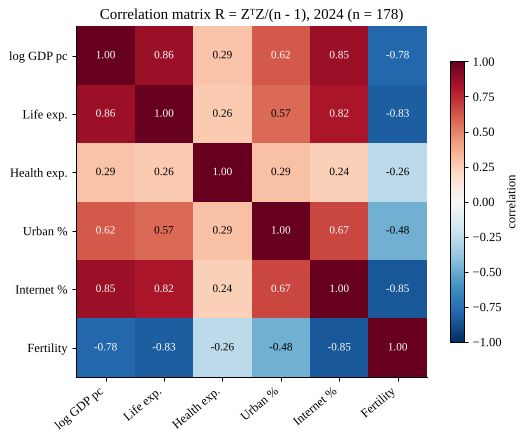

In [13]:
# Report Figure 1: heat-map of R (interpretation of Z^T Z)
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
labels = ["log GDP pc", "Life exp.", "Health exp.", "Urban %", "Internet %", "Fertility"]
ax.set_xticks(range(p)); ax.set_xticklabels(labels, rotation=40, ha="right")
ax.set_yticks(range(p)); ax.set_yticklabels(labels)
ax.grid(False)
for i in range(p):
    for j in range(p):
        ax.text(j, i, f"{R[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(R[i, j]) > 0.6 else "black", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8, label="correlation")
ax.set_title(f"Correlation matrix R = ZᵀZ/(n - 1), {LATEST} (n = {n})")
fig.tight_layout(); fig.savefig("figures/fig5_correlation_matrix.png"); plt.show()

In [14]:
# Determinant-based analysis
det_XtX = np.linalg.det(XtX)
sign, logdet = np.linalg.slogdet(XtX)        # stable log-determinant
det_R = np.linalg.det(R)
eig = np.linalg.eigvalsh(R)[::-1]            # eigenvalues of R, descending
cond_R = eig.max() / eig.min()

# det(R) = product of eigenvalues (check) and share of variance on the first component
print(f"det(X^T X) = {det_XtX:.4e} (log = {logdet:.3f}), scale dependent, hard to interpret")
print(f"det(R) = {det_R:.5f}; product of eigenvalues = {np.prod(eig):.5f}")
print("Eigenvalues of R:", eig.round(4), "| first PC explains", f"{eig[0]/p:.1%}")
print(f"Condition number of R = {cond_R:.2f}")

# 2x2 sub-determinants: det = 1 - r^2 = share of 'non-shared' variation for a pair
pairs = [("log_gdp", "internet"), ("life_exp", "fertility"), ("log_gdp", "health_exp")]
for a, b in pairs:
    i, j = cols.index(a), cols.index(b)
    sub = R[np.ix_([i, j], [i, j])]
    print(f"det R[{a}, {b}] = {np.linalg.det(sub):.4f}  (r = {R[i, j]:.3f})")

# Variance inflation factors: diagonal of R^{-1}
R_inv = np.linalg.inv(R)
vif = pd.Series(np.diag(R_inv), index=cols)
print("VIF = diag(R^-1):\n", vif.round(3).to_string())

det(X^T X) = 4.3024e+22 (log = 52.116), scale dependent, hard to interpret
det(R) = 0.00661; product of eigenvalues = 0.00661
Eigenvalues of R: [4.0685 0.9022 0.5637 0.213  0.1573 0.0953] | first PC explains 67.8%
Condition number of R = 42.70
det R[log_gdp, internet] = 0.2725  (r = 0.853)
det R[life_exp, fertility] = 0.3155  (r = -0.827)
det R[log_gdp, health_exp] = 0.9167  (r = 0.289)
VIF = diag(R^-1):
 log_gdp      5.2730
life_exp     5.0080
health_exp   1.1410
urban        2.0400
internet     6.4370
fertility    4.7750


In [15]:
# Practical consequence: least-squares via the normal equations beta = (A^T A)^{-1} A^T y
# predicting life expectancy from the other five standardised variables
y = Z[:, cols.index("life_exp")]
A = np.column_stack([np.ones(n), np.delete(Z, cols.index("life_exp"), axis=1)])
AtA = A.T @ A
beta = np.linalg.solve(AtA, A.T @ y)            # solve rather than invert, for numerical stability
resid = y - A @ beta
r2 = 1 - (resid @ resid) / (y @ y)
print(f"det(A^T A / n) = {np.linalg.det(AtA / n):.4f}")
beta_s = pd.Series(beta, index=["intercept"] + [c for c in cols if c != "life_exp"])
print("Standardised coefficients:\n", beta_s.round(4).to_string())
print(f"R^2 = {r2:.4f}")

mat_tab = pd.DataFrame({"Value": [n, p, logdet, det_R, eig[0], eig[-1], eig[0] / p, cond_R,
                                   vif.max(), r2]},
                       index=["n (rows of X)", "p (columns)", r"log det($X^TX$)", "det(R)",
                              "Largest eigenvalue of R", "Smallest eigenvalue of R",
                              "Share of variance, 1st PC", "Condition number of R",
                              f"Max VIF ({vif.idxmax()})", "R² (normal equations)"])
eig_tab = pd.DataFrame({"eigenvalue": eig, "share": eig / p, "VIF (by variable)": vif.values},
                       index=[f"λ{k+1} / {c}" for k, c in enumerate(cols)])
tab4 = pd.DataFrame([
    ["Rows of X (countries)", f"{n}"], ["Columns of X (variables)", f"{p}"],
    ["log det(XᵀX)", f(logdet, 2)], ["det(R)", f(det_R, 4)],
    ["Largest eigenvalue of R", f(eig[0], 2)], ["Smallest eigenvalue of R", f(eig[-1], 3)],
    ["Share of variance on the first component", f"{eig[0] / p * 100:.1f}%"],
    ["Condition number of R", f(cond_R, 1)], [f"Largest VIF ({NAMES[vif.idxmax()].split(' (')[0].lower().replace('users', 'use')})", f(vif.max(), 2)],
    ["R² of the regression (normal equations)", f(r2, 2)],
], columns=["Quantity", "Value"])
save_table(tab4, "tab2c_determinant", "Determinant, eigenvalue and regression results", values=mat_tab)
LONG = {"log_gdp": "ln GDP per capita", **NAMES}
tab_beta = pd.DataFrame([["Intercept" if k == "intercept" else LONG[k], f(v, 3)] for k, v in beta_s.items()],
                        columns=["Predictor", "β (standardised)"])
save_table(tab_beta, "tab2d_normal_eq", "Normal equations: life expectancy on five predictors", values=beta_s.to_frame("beta"))
tab4

det(A^T A / n) = 0.0322
Standardised coefficients:
 intercept    -0.0000
log_gdp       0.4945
health_exp   -0.0069
urban         0.0566
internet      0.0287
fertility    -0.3899
R^2 = 0.8003


,Quantity,Value
0,Rows of X (countries),178
1,Columns of X (variables),6
2,log det(XᵀX),52.12
3,det(R),0.0066
4,Largest eigenvalue of R,4.07
5,Smallest eigenvalue of R,0.095
6,Share of variance on the first component,67.8%
7,Condition number of R,42.7
8,Largest VIF (internet use),6.44
9,R² of the regression (normal equations),0.80


## 4. Task 2.3: Descriptive statistics and EDA

Key variables: **life expectancy** and **GDP per capita** (2024). Formulas implemented by hand and checked with SciPy:

$\bar x=\frac1n\sum x_i,\qquad s^2=\frac1{n-1}\sum (x_i-\bar x)^2,\qquad
g_1=\frac{\frac1n\sum(x_i-\bar x)^3}{\left(\frac1n\sum(x_i-\bar x)^2\right)^{3/2}},\qquad
g_2=\frac{\frac1n\sum(x_i-\bar x)^4}{\left(\frac1n\sum(x_i-\bar x)^2\right)^{2}}-3$

($g_2$ is excess kurtosis: 0 for a normal distribution.)

In [16]:
def describe_by_hand(x):
    # Moment-based summary statistics implemented from the formulas above
    x = np.asarray(x, dtype=float); x = x[~np.isnan(x)]
    n = len(x); mean = x.sum() / n; d = x - mean
    m2, m3, m4 = (d**2).mean(), (d**3).mean(), (d**4).mean()
    return {"n": n, "mean": mean, "median": np.median(x), "variance (s²)": (d**2).sum() / (n - 1),
            "std dev (s)": np.sqrt((d**2).sum() / (n - 1)), "skewness g1": m3 / m2**1.5,
            "excess kurtosis g2": m4 / m2**2 - 3, "min": x.min(), "max": x.max()}

desc = pd.DataFrame({
    "Life expectancy (years)": describe_by_hand(df22["life_exp"]),
    "GDP per capita (US$)": describe_by_hand(df22["gdp_pc"]),
    "log GDP per capita": describe_by_hand(df22["log_gdp"]),
})
# Check against SciPy (biased moment estimators, same as the formulas above)
for c, col in [("Life expectancy (years)", "life_exp"), ("GDP per capita (US$)", "gdp_pc")]:
    x = df22[col].dropna()
    assert np.isclose(desc.loc["skewness g1", c], stats.skew(x))
    assert np.isclose(desc.loc["excess kurtosis g2", c], stats.kurtosis(x))
print("Hand-computed skewness and kurtosis match scipy.stats")
# Year sensitivity: the same statistics for 2022, when the Central African Republic (CAF) recorded LE = 18.8 years
le22 = panel.loc[panel["year"] == 2022, "life_exp"]
desc["Life expectancy, 2022"] = describe_by_hand(le22)
caf = panel.set_index(["code", "year"])["life_exp"]
print(f"CAF life expectancy: 2022 = {caf[('CAF', 2022)]:.1f}, {LATEST} = {caf[('CAF', LATEST)]:.1f}")
print(f"Lowest {LATEST} values:\n", df22.nsmallest(3, "life_exp")[["country", "life_exp"]].to_string(index=False))
le_, gdp_, lg_, le22_ = [desc.iloc[:, j] for j in range(4)]
i0 = lambda v: f(v, 0)
def row(label, stat, gdp_fmt=lambda v: f(v, 2)):
    return [label, f(le_[stat]), gdp_fmt(gdp_[stat]), f(lg_[stat]), f(le22_[stat])]
var_g = gdp_["variance (s²)"]; expo = int(np.floor(np.log10(var_g)))
tab5 = pd.DataFrame([
    ["n"] + [f"{int(c['n'])}" for c in (le_, gdp_, lg_, le22_)],
    row("Mean", "mean", i0), row("Median", "median", i0),
    ["Variance (s²)", f(le_["variance (s²)"]), f"{var_g / 10**expo:.2f} × 10{str(expo).translate(str.maketrans('0123456789', '⁰¹²³⁴⁵⁶⁷⁸⁹'))}",
     f(lg_["variance (s²)"]), f(le22_["variance (s²)"])],
    row("Standard deviation (s)", "std dev (s)", i0),
    row("Skewness (g₁)", "skewness g1"), row("Excess kurtosis (g₂)", "excess kurtosis g2"),
    row("Minimum", "min", i0), row("Maximum", "max", i0),
], columns=["Statistic", f"Life expectancy {LATEST} (years)", f"GDP per capita {LATEST} (US$)",
            f"ln GDP per capita {LATEST}", "Life expectancy 2022 (years)"])
save_table(tab5, "tab3_descriptives", f"Summary statistics, {LATEST} (with 2022 life expectancy for comparison)", values=desc)
tab5

Hand-computed skewness and kurtosis match scipy.stats
CAF life expectancy: 2022 = 18.8, 2024 = 57.7
Lowest 2024 values:
                  country  life_exp
                 Nigeria   54.6350
                    Chad   55.2380
Central African Republic   57.6710


,Statistic,Life expectancy 2024 (years),GDP per capita 2024 (US$),ln GDP per capita 2024,Life expectancy 2022 (years)
0,n,218,201,201,218
1,Mean,73.97,"22,262",9.06,73.07
2,Median,74.70,"7,754",8.96,74.19
3,Variance (s²),50.67,1.24 × 10⁹,2.16,63.17
4,Standard deviation (s),7.12,"35,254",1.47,7.95
5,Skewness (g₁),-0.41,3.81,-0.05,-1.71
6,Excess kurtosis (g₂),-0.61,20.48,-0.75,8.58
7,Minimum,54.63,216,5.38,18.82
8,Maximum,86.50,"288,002",12.57,85.75


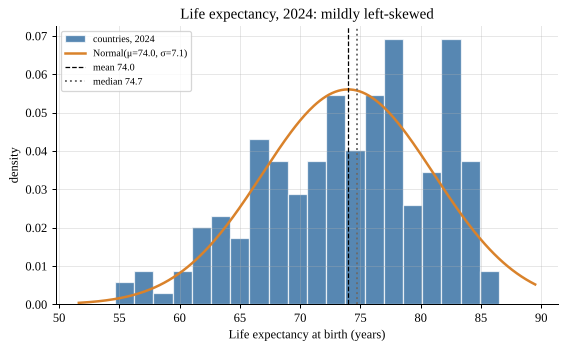

In [17]:
# Report Figure 2: histogram of life expectancy with fitted normal density
le = df22["life_exp"].dropna()
mu, sd = le.mean(), le.std(ddof=1)
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.hist(le, bins=20, density=True, color=BLUE, alpha=0.75, edgecolor="white", label=f"countries, {LATEST}")
grid = np.linspace(le.min() - 3, le.max() + 3, 300)
ax.plot(grid, stats.norm.pdf(grid, mu, sd), color=ORANGE, lw=2, label=f"Normal(μ={mu:.1f}, σ={sd:.1f})")
ax.axvline(le.mean(), color="k", ls="--", lw=1, label=f"mean {le.mean():.1f}")
ax.axvline(le.median(), color=GREY, ls=":", lw=1.5, label=f"median {le.median():.1f}")
ax.set_xlabel("Life expectancy at birth (years)"); ax.set_ylabel("density")
ax.set_title(f"Life expectancy, {LATEST}: mildly left-skewed")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig("figures/fig1_hist_life_expectancy.png"); plt.show()

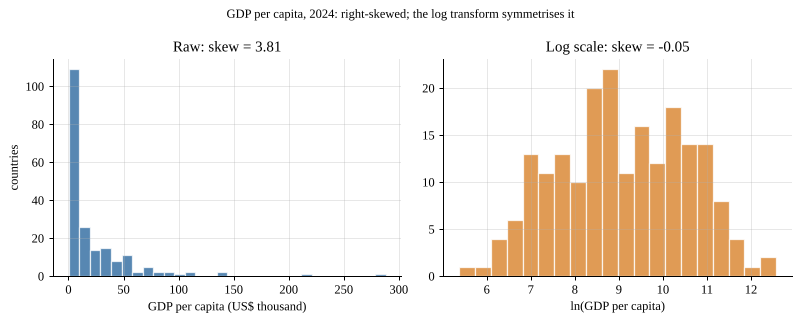

In [18]:
# Report Figure 3: GDP per capita on the raw and log scale
g = df22["gdp_pc"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].hist(g / 1000, bins=30, color=BLUE, alpha=0.75, edgecolor="white")
axes[0].set_xlabel("GDP per capita (US$ thousand)"); axes[0].set_ylabel("countries")
axes[0].set_title(f"Raw: skew = {stats.skew(g):.2f}")
axes[1].hist(np.log(g), bins=20, color=ORANGE, alpha=0.8, edgecolor="white")
axes[1].set_xlabel("ln(GDP per capita)")
axes[1].set_title(f"Log scale: skew = {stats.skew(np.log(g)):.2f}")
fig.suptitle(f"GDP per capita, {LATEST}: right-skewed; the log transform symmetrises it", fontsize=10)
fig.tight_layout(); fig.savefig("figures/fig2_hist_gdp_raw_vs_log.png"); plt.show()

Each 1% higher GDP pc ~ 0.042 more years; doubling GDP pc ~ 2.90 years


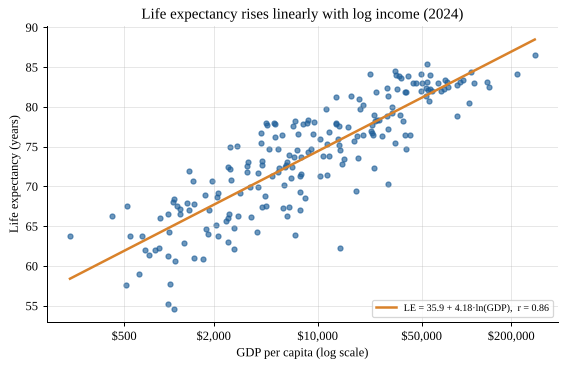

In [19]:
# Report Figure 4: scatterplot of life expectancy against log GDP with least-squares line
sc = df22[["log_gdp", "life_exp", "gdp_pc"]].dropna()
slope, intercept, r, pval, se = stats.linregress(sc["log_gdp"], sc["life_exp"])
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.scatter(sc["log_gdp"], sc["life_exp"], s=16, color=BLUE, alpha=0.65)
xs = np.linspace(sc["log_gdp"].min(), sc["log_gdp"].max(), 50)
ax.plot(xs, intercept + slope * xs, color=ORANGE, lw=2,
        label=f"LE = {intercept:.1f} + {slope:.2f}·ln(GDP),  r = {r:.2f}")
ticks = [500, 2000, 10000, 50000, 200000]
ax.set_xticks(np.log(ticks)); ax.set_xticklabels([f"${t:,}" for t in ticks])
ax.set_xlabel("GDP per capita (log scale)"); ax.set_ylabel("Life expectancy (years)")
ax.set_title(f"Life expectancy rises linearly with log income ({LATEST})")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig("figures/fig3_scatter_loggdp_life_exp.png"); plt.show()
print(f"Each 1% higher GDP pc ~ {slope/100:.3f} more years; doubling GDP pc ~ {slope*np.log(2):.2f} years")

Lower-income: n=100, Q1=64.8, median=68.3, Q3=72.5, IQR=7.7, outliers=0
Higher-income: n=101, Q1=76.4, median=79.0, Q3=82.5, IQR=6.1, outliers=1


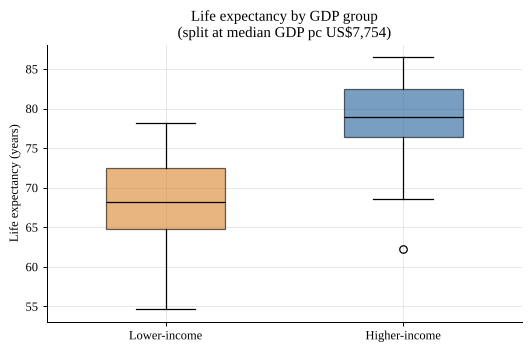

In [20]:
# Report Figure 5: boxplots of life expectancy by self-defined income group, with IQR / outlier fences
grp = df22.dropna(subset=["life_exp", "income_grp"])
data = [grp.loc[grp["income_grp"] == k, "life_exp"] for k in ["Lower-income", "Higher-income"]]
fig, ax = plt.subplots(figsize=(6.0, 4))
bp = ax.boxplot(data, patch_artist=True, widths=0.5, medianprops=dict(color="k"))
ax.set_xticks([1, 2]); ax.set_xticklabels(["Lower-income", "Higher-income"])
for patch, col in zip(bp["boxes"], [ORANGE, BLUE]):
    patch.set_facecolor(col); patch.set_alpha(0.6)
ax.set_ylabel("Life expectancy (years)")
ax.set_title(f"Life expectancy by GDP group\n(split at median GDP pc US${gdp_median:,.0f})")
fig.tight_layout(); fig.savefig("figures/fig4_boxplot_life_exp_by_group.png"); plt.show()

for k, d in zip(["Lower-income", "Higher-income"], data):
    q1, q3 = np.percentile(d, [25, 75]); iqr = q3 - q1
    outl = d[(d < q1 - 1.5 * iqr) | (d > q3 + 1.5 * iqr)]
    print(f"{k}: n={len(d)}, Q1={q1:.1f}, median={d.median():.1f}, Q3={q3:.1f}, IQR={iqr:.1f}, outliers={len(outl)}")

        mean  median      Q1      Q3
year                                
2015 72.0700 73.5400 65.9400 78.2400
2016 72.3000 73.6600 66.3200 78.3600
2017 72.4500 74.0100 66.6600 78.6000
2018 72.8200 73.9700 66.9700 78.7200
2019 72.9800 74.1100 67.2000 78.7500
2020 72.4600 72.8900 66.9300 78.0300
2021 71.7500 72.2000 66.2600 77.2300
2022 73.0700 74.1900 67.7300 78.4500
2023 73.7500 74.5200 68.3700 79.4000
2024 73.9700 74.7000 68.7200 79.6600


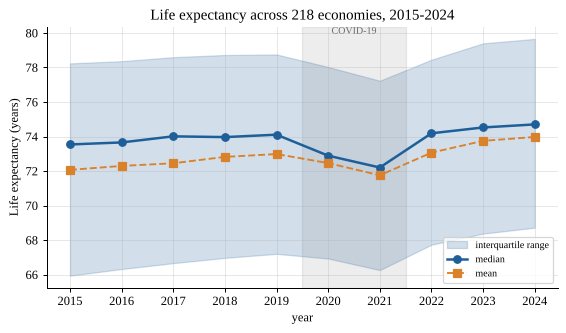

In [21]:
# Report Figure 6: life expectancy over time, 2015-2024, showing the COVID-19 dip and recovery (latest data)
yrs = panel[panel["year"] <= LATEST].groupby("year")["life_exp"]
q = yrs.quantile([0.25, 0.5, 0.75]).unstack()
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.fill_between(q.index, q[0.25], q[0.75], color=BLUE, alpha=0.2, label="interquartile range")
ax.plot(q.index, q[0.5], color=BLUE, marker="o", lw=2, label="median")
ax.plot(q.index, yrs.mean(), color=ORANGE, marker="s", lw=1.5, ls="--", label="mean")
ax.axvspan(2019.5, 2021.5, color=GREY, alpha=0.12)
ax.text(2020.5, q[0.75].max() + 0.3, "COVID-19", ha="center", fontsize=8, color=GREY)
ax.set_xticks(q.index); ax.set_xlabel("year"); ax.set_ylabel("Life expectancy (years)")
ax.set_title(f"Life expectancy across 218 economies, 2015-{LATEST}")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig("figures/fig9_trend_life_expectancy.png"); plt.show()
trend_tab = pd.DataFrame({"mean": yrs.mean(), "median": q[0.5], "Q1": q[0.25], "Q3": q[0.75]})
print(trend_tab.round(2).to_string())

## 5. Task 2.4: Random variables and probability

**Discrete random variable.** $K$ = number of the nine year-on-year changes (2015→2016, …, 2023→2024) in which a
country's life expectancy **increased**, $K\in\{0,1,\dots,9\}$. Empirical PMF $\hat p(k)=\#\{K=k\}/N$.
If the yearly changes were independent with common probability $p$, then $K\sim\text{Binomial}(9,p)$ with
$P(K=k)=\binom9k p^k(1-p)^{9-k}$, $E[K]=9p$, $\operatorname{Var}(K)=9p(1-p)$.

**Continuous random variable.** Life expectancy $L$ (2024) modelled as $L\sim N(\mu,\sigma^2)$ with $\hat\mu=\bar x$, $\hat\sigma=s$:
$P(a<L<b)=\Phi\!\left(\frac{b-\mu}\sigma\right)-\Phi\!\left(\frac{a-\mu}\sigma\right)$, compared with empirical relative frequencies.
GDP per capita is modelled as **log-normal**: $\ln G\sim N(\mu_{\ln},\sigma^2_{\ln})$.

In [22]:
# Discrete RV: K = number of yearly increases in life expectancy, 2015-2024 (9 changes per country)
wide_le = panel[panel["year"] <= LATEST].pivot(index="code", columns="year", values="life_exp").dropna()
inc = (wide_le.diff(axis=1).iloc[:, 1:] > 0)     # Bernoulli trials: 1 = life expectancy rose that year
T = inc.shape[1]
K = inc.sum(axis=1).astype(int)
N = len(K)
ks = np.arange(T + 1)

pmf_emp = K.value_counts().reindex(ks, fill_value=0).sort_index() / N
p_hat = inc.to_numpy().mean()                    # pooled probability of an increase
pmf_bin = stats.binom.pmf(ks, T, p_hat)

EK, VarK = (ks * pmf_emp).sum(), K.var(ddof=0)
print(f"T = {T} trials per country; N = {N} countries; p_hat = {p_hat:.4f}")
print(f"Empirical E[K] = {EK:.3f}, Var[K] = {VarK:.3f}")
print(f"Binomial  E[K] = {T*p_hat:.3f}, Var[K] = {T*p_hat*(1-p_hat):.3f}")
print("Share of increases by year-pair:\n", inc.mean().round(3).to_string())

cut = T - 4
prob_disc = pd.DataFrame({"empirical P(K=k)": pmf_emp.values, f"Binomial({T}, p̂)": pmf_bin}, index=[f"k = {k}" for k in ks])
prob_disc.loc[f"P(K = {T})"] = [pmf_emp[T], pmf_bin[T]]
prob_disc.loc[f"P(K ≤ {cut})"] = [pmf_emp[:cut + 1].sum(), stats.binom.cdf(cut, T, p_hat)]
prob_disc.loc["E[K]"] = [EK, T * p_hat]
prob_disc.loc["Var[K]"] = [VarK, T * p_hat * (1 - p_hat)]
p3 = lambda v: "<0.001" if 0 < v < 0.0005 else f(v, 3)
tab6 = pd.DataFrame([[f"k = {k}", p3(pmf_emp[k]), p3(pmf_bin[k])] for k in ks] + [
    [f"P(K = {T})", p3(pmf_emp[T]), p3(pmf_bin[T])],
    [f"P(K ≤ {cut})", p3(pmf_emp[:cut + 1].sum()), p3(stats.binom.cdf(cut, T, p_hat))],
    ["E[K]", f(EK, 2), f(T * p_hat, 2)],
    ["Var(K)", f(VarK, 3), f(T * p_hat * (1 - p_hat), 3)],
], columns=["", "Observed", f"Binomial({T}, {p_hat:.3f})"])
save_table(tab6, "tab4a_discrete", "Empirical and binomial probabilities for K", values=prob_disc)
tab6

T = 9 trials per country; N = 218 countries; p_hat = 0.7472
Empirical E[K] = 6.725, Var[K] = 1.741
Binomial  E[K] = 6.725, Var[K] = 1.700
Share of increases by year-pair:
 year
2016   0.8440
2017   0.8120
2018   0.8810
2019   0.8580
2020   0.2980
2021   0.2800
2022   0.8760
2023   0.9270
2024   0.9500


,,Observed,"Binomial(9, 0.747)"
0,k = 0,0.000,<0.001
1,k = 1,0.000,<0.001
2,k = 2,0.005,0.001
3,k = 3,0.009,0.009
4,k = 4,0.055,0.041
5,k = 5,0.101,0.120
6,k = 6,0.197,0.236
7,k = 7,0.339,0.299
8,k = 8,0.239,0.221
9,k = 9,0.055,0.073


Cells: K<=4, ..., K>=9; expected counts = [11.1 26.1 51.5 65.2 48.2 15.8]
Chi-square = 5.79, df = 4, p-value = 0.215


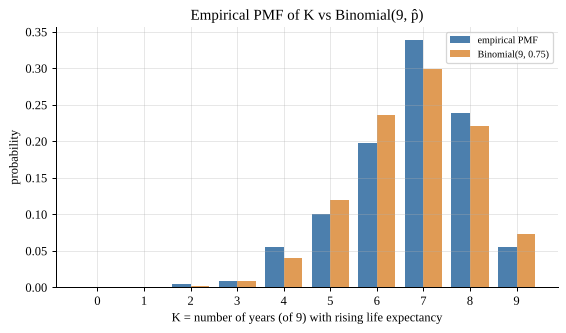

In [23]:
# Report Figure 7: empirical PMF vs binomial model
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.bar(ks - 0.2, pmf_emp.values, width=0.4, color=BLUE, alpha=0.8, label="empirical PMF")
ax.bar(ks + 0.2, pmf_bin, width=0.4, color=ORANGE, alpha=0.8, label=f"Binomial({T}, {p_hat:.2f})")
ax.set_xticks(ks); ax.set_xlabel(f"K = number of years (of {T}) with rising life expectancy")
ax.set_ylabel("probability")
ax.set_title(f"Empirical PMF of K vs Binomial({T}, p̂)")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("figures/fig6_pmf_discrete.png"); plt.show()

# Goodness of fit: chi-square, pooling the lowest cells until every expected count is >= 5
exp_counts, obs_counts = pmf_bin * N, pmf_emp.values * N
lo = 0
while exp_counts[:lo + 1].sum() < 5: lo += 1
hi = T
while exp_counts[hi:].sum() < 5: hi -= 1
obs = np.r_[obs_counts[:lo + 1].sum(), obs_counts[lo + 1:hi], obs_counts[hi:].sum()]
exp = np.r_[exp_counts[:lo + 1].sum(), exp_counts[lo + 1:hi], exp_counts[hi:].sum()]
chi2 = ((obs - exp) ** 2 / exp).sum(); dfree = len(obs) - 1 - 1   # minus 1 estimated parameter
print(f"Cells: K<={lo}, ..., K>={hi}; expected counts = {np.round(exp, 1)}")
print(f"Chi-square = {chi2:.2f}, df = {dfree}, p-value = {stats.chi2.sf(chi2, dfree):.3g}")

In [24]:
# Continuous RV: life expectancy ~ Normal(mu, sigma); compare model and empirical probabilities
le = df22["life_exp"].dropna(); mu, sd = le.mean(), le.std(ddof=1)
events = {
    "P(L > 80)":      (lambda x: x > 80,               1 - stats.norm.cdf(80, mu, sd)),
    "P(L < 60)":      (lambda x: x < 60,               stats.norm.cdf(60, mu, sd)),
    "P(65 < L < 75)": (lambda x: (x > 65) & (x < 75),  stats.norm.cdf(75, mu, sd) - stats.norm.cdf(65, mu, sd)),
    "P(|L-μ| < σ)":   (lambda x: abs(x - mu) < sd,     stats.norm.cdf(1) - stats.norm.cdf(-1)),
}
rows = {k: [ev(le).mean(), model] for k, (ev, model) in events.items()}

# Log-normal model for GDP per capita
lg = df22["log_gdp"].dropna(); mu_l, sd_l = lg.mean(), lg.std(ddof=1)
gdp = df22["gdp_pc"].dropna()
rows["P(GDP pc > $20,000)"] = [(gdp > 20000).mean(), 1 - stats.norm.cdf(np.log(20000), mu_l, sd_l)]
rows["P(GDP pc < $1,500)"]  = [(gdp < 1500).mean(),  stats.norm.cdf(np.log(1500), mu_l, sd_l)]
prob_cont = pd.DataFrame(rows, index=["empirical", "model"]).T
prob_cont["difference"] = prob_cont["model"] - prob_cont["empirical"]

# z-score working for one event, shown explicitly
z80 = (80 - mu) / sd
print(f"L ~ N({mu:.3f}, {sd:.3f}^2): z = (80 - {mu:.2f}) / {sd:.2f} = {z80:.3f}; P(L > 80) = 1 - Φ({z80:.3f}) = {1 - stats.norm.cdf(z80):.4f}")
print(f"ln(GDP) ~ N({mu_l:.3f}, {sd_l:.3f}^2)")
# Normality diagnostics (Shapiro-Wilk)
print("Shapiro-Wilk p-values: life_exp =", f"{stats.shapiro(le).pvalue:.2e}", "| log GDP =", f"{stats.shapiro(lg).pvalue:.3f}")
labels7 = ["P(L > 80)", "P(L < 60)", "P(65 < L < 75)", "P(|L - μ| < σ)",
           "P(GDP per capita > $20,000)", "P(GDP per capita < $1,500)"]
models7 = ["Normal"] * 4 + ["Log-normal"] * 2
tab7 = pd.DataFrame([[labels7[i], models7[i], f(r["empirical"], 3), f(r["model"], 3), f(r["difference"], 3)]
                     for i, (_, r) in enumerate(prob_cont.iterrows())],
                    columns=["Event", "Model", "Observed", "Model value", "Difference"])
save_table(tab7, "tab4b_continuous", "Normal and log-normal model probabilities against observed frequencies", values=prob_cont)
tab7

L ~ N(73.973, 7.118^2): z = (80 - 73.97) / 7.12 = 0.847; P(L > 80) = 1 - Φ(0.847) = 0.1986
ln(GDP) ~ N(9.062, 1.471^2)
Shapiro-Wilk p-values: life_exp = 8.19e-05 | log GDP = 0.064


,Event,Model,Observed,Model value,Difference
0,P(L > 80),Normal,0.239,0.199,-0.040
1,P(L < 60),Normal,0.028,0.025,-0.003
2,P(65 < L < 75),Normal,0.385,0.454,0.068
3,P(|L - μ| < σ),Normal,0.615,0.683,0.068
4,"P(GDP per capita > $20,000)",Log-normal,0.328,0.284,-0.045
5,"P(GDP per capita < $1,500)",Log-normal,0.154,0.117,-0.037


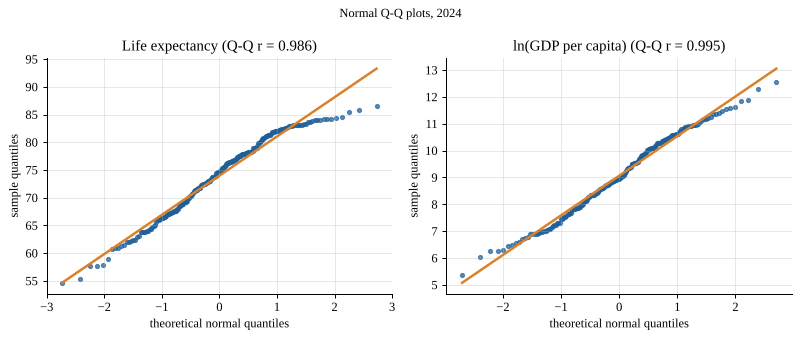

In [25]:
# Report Figure 8: normal Q-Q plots, life expectancy vs log GDP
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, series, title in [(axes[0], le, "Life expectancy"), (axes[1], lg, "ln(GDP per capita)")]:
    (osm, osr), (sl, ic, rr) = stats.probplot(series, dist="norm")
    ax.scatter(osm, osr, s=10, color=BLUE, alpha=0.7)
    ax.plot(osm, sl * osm + ic, color=ORANGE, lw=2)
    ax.set_xlabel("theoretical normal quantiles"); ax.set_ylabel("sample quantiles")
    ax.set_title(f"{title} (Q-Q r = {rr:.3f})")
fig.suptitle(f"Normal Q-Q plots, {LATEST}", fontsize=10)
fig.tight_layout(); fig.savefig("figures/fig7_qq_plots.png"); plt.show()

## 6. Task 2.5: Interval estimates (95%)

| Interval | Formula |
|---|---|
| one-sample mean | $\bar x\pm t_{0.975,\,n-1}\,s/\sqrt n$ |
| one-sample proportion (Wald) | $\hat p\pm z_{0.975}\sqrt{\hat p(1-\hat p)/n}$ |
| two-sample mean difference (Welch) | $(\bar x_1-\bar x_2)\pm t_{0.975,\,\nu}\sqrt{s_1^2/n_1+s_2^2/n_2}$, Welch-Satterthwaite $\nu$ |
| two-sample proportion difference | $(\hat p_1-\hat p_2)\pm z_{0.975}\sqrt{\hat p_1(1-\hat p_1)/n_1+\hat p_2(1-\hat p_2)/n_2}$ |

Definitions used (2024; health expenditure = latest available value, 2023):
* mean: life expectancy of all countries;
* proportion: share of countries with **internet use ≥ 75%** of the population;
* two means: life expectancy, Higher-income vs Lower-income group (median GDP split);
* two proportions: share of countries spending **≥ 6% of GDP on health**, Higher- vs Lower-income.

In [26]:
z = stats.norm.ppf(0.975)
ci_rows = {}

# (1) One-sample mean: life expectancy
x = df22["life_exp"].dropna(); n1 = len(x)
t1 = stats.t.ppf(0.975, n1 - 1); se1 = x.std(ddof=1) / np.sqrt(n1)
ci_rows["Mean life expectancy (years)"] = [n1, x.mean(), se1, t1, x.mean() - t1 * se1, x.mean() + t1 * se1]
print(f"(1) xbar = {x.mean():.3f}, s = {x.std(ddof=1):.3f}, n = {n1}, SE = {se1:.4f}, t = {t1:.4f}")

# (2) One-sample proportion: internet >= 75%
it = df22["internet"].dropna(); n2 = len(it); x2 = int((it >= 75).sum()); ph = x2 / n2
se2 = np.sqrt(ph * (1 - ph) / n2)
ci_rows["Proportion internet ≥ 75%"] = [n2, ph, se2, z, ph - z * se2, ph + z * se2]
print(f"(2) x = {x2}, n = {n2}, p_hat = {ph:.4f}, SE = {se2:.4f}; checks n*p = {n2*ph:.0f}, n*(1-p) = {n2*(1-ph):.0f}")

# (3) Two-sample mean difference (Welch): life expectancy, Higher - Lower income
a = df22.loc[df22["income_grp"] == "Higher-income", "life_exp"].dropna()
b = df22.loc[df22["income_grp"] == "Lower-income", "life_exp"].dropna()
va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
se3 = np.sqrt(va + vb)
nu = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))   # Welch-Satterthwaite df
t3 = stats.t.ppf(0.975, nu); d3 = a.mean() - b.mean()
ci_rows["Mean LE: Higher minus Lower income"] = [len(a) + len(b), d3, se3, t3, d3 - t3 * se3, d3 + t3 * se3]
print(f"(3) means {a.mean():.3f} (n={len(a)}) vs {b.mean():.3f} (n={len(b)}); SE = {se3:.4f}; Welch df = {nu:.1f}")

# (4) Two-sample proportion difference: health expenditure >= 6% of GDP, Higher - Lower income
h = df22.dropna(subset=["health_exp", "income_grp"])
hA = h.loc[h["income_grp"] == "Higher-income", "health_exp"] >= 6
hB = h.loc[h["income_grp"] == "Lower-income", "health_exp"] >= 6
pA, pB = hA.mean(), hB.mean()
se4 = np.sqrt(pA * (1 - pA) / len(hA) + pB * (1 - pB) / len(hB)); d4 = pA - pB
ci_rows["Prop. health exp ≥ 6%: Higher minus Lower"] = [len(hA) + len(hB), d4, se4, z, d4 - z * se4, d4 + z * se4]
print(f"(4) p1 = {pA:.4f} ({hA.sum()}/{len(hA)}) vs p2 = {pB:.4f} ({hB.sum()}/{len(hB)}); SE = {se4:.4f}")

ci = pd.DataFrame(ci_rows, index=["n", "estimate", "std. error", "critical value", "95% lower", "95% upper"]).T
ci["n"] = ci["n"].astype(int)
labels8 = ["Mean life expectancy (years)", "Proportion with internet use ≥ 75%",
           "Difference in mean life expectancy, higher minus lower income (years)",
           "Difference in proportion spending ≥ 6% of GDP on health, higher minus lower income"]
dec8, crit8 = [2, 3, 2, 3], ["t", "z", "t", "z"]
tab8 = pd.DataFrame([[labels8[i], f"{int(r['n'])}", f(r["estimate"], dec8[i]), f(r["std. error"], 3),
                      f"{crit8[i]} = {r['critical value']:.3f}",
                      f"[{f(r['95% lower'], dec8[i])}, {f(r['95% upper'], dec8[i])}]"]
                     for i, (_, r) in enumerate(ci.iterrows())],
                    columns=["Interval", "n", "Estimate", "SE", "Critical value", "95% CI"])
save_table(tab8, "tab5_confidence_intervals", f"95% confidence intervals, {LATEST}", values=ci)
tab8

(1) xbar = 73.973, s = 7.118, n = 218, SE = 0.4821, t = 1.9710
(2) x = 109, n = 182, p_hat = 0.5989, SE = 0.0363; checks n*p = 109, n*(1-p) = 73
(3) means 78.978 (n=101) vs 68.587 (n=100); SE = 0.6897; Welch df = 189.8
(4) p1 = 0.6629 (59/89) vs p2 = 0.4141 (41/99); SE = 0.0704


,Interval,n,Estimate,SE,Critical value,95% CI
0,Mean life expectancy (years),218,73.97,0.482,t = 1.971,"[73.02, 74.92]"
1,Proportion with internet use ≥ 75%,182,0.599,0.036,z = 1.960,"[0.528, 0.670]"
2,"Difference in mean life expectancy, higher minus lower income (years)",201,10.39,0.690,t = 1.973,"[9.03, 11.75]"
3,"Difference in proportion spending ≥ 6% of GDP on health, higher minus lower income",188,0.249,0.070,z = 1.960,"[0.111, 0.387]"


In [27]:
# Cross-check (3) with SciPy's Welch t-test confidence interval
res = stats.ttest_ind(a, b, equal_var=False)
print("SciPy Welch CI:", np.round(res.confidence_interval(0.95), 4))

# Wilson score interval for (2) as a robustness check on the Wald interval
centre = (ph + z**2 / (2 * n2)) / (1 + z**2 / n2)
half = z * np.sqrt(ph * (1 - ph) / n2 + z**2 / (4 * n2**2)) / (1 + z**2 / n2)
print(f"Wilson CI for internet proportion: ({centre - half:.4f}, {centre + half:.4f})")

SciPy Welch CI: [ 9.03   11.7508]
Wilson CI for internet proportion: (0.5264, 0.6674)


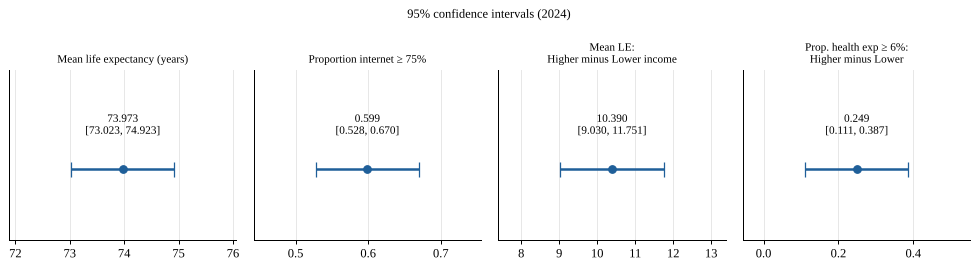

In [28]:
# Report Figure 9: the four intervals (separate panels because units differ)
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, (name, row) in zip(axes, ci.iterrows()):
    ax.errorbar(row["estimate"], 0, xerr=[[row["estimate"] - row["95% lower"]], [row["95% upper"] - row["estimate"]]],
                fmt="o", color=BLUE, capsize=6, lw=2)
    ax.set_yticks([]); ax.set_title(name.replace(": ", ":\n"), fontsize=9)
    ax.text(row["estimate"], 0.25, f"{row['estimate']:.3f}\n[{row['95% lower']:.3f}, {row['95% upper']:.3f}]",
            ha="center", fontsize=9); ax.set_ylim(-0.5, 0.7)
    lo, hi = row["95% lower"], row["95% upper"]; pad = (hi - lo) * 0.6
    ax.set_xlim(lo - pad, hi + pad)
fig.suptitle(f"95% confidence intervals ({LATEST})", fontsize=10)
fig.tight_layout(); fig.savefig("figures/fig8_confidence_intervals.png"); plt.show()

## 7. Outputs supporting the critical reflection (Task 3)

Checks of the assumptions behind the methods above.

In [29]:
# (a) Independence over time: share of countries with rising life expectancy by year (COVID shock)
by_year = inc.mean()
print("Share of countries with rising LE, by year-pair:\n", by_year.round(3).to_string())

# (b) Normality: Shapiro-Wilk for the variables used in t-intervals
for name, s_ in [("life_exp (all)", le), ("life_exp Higher-income", a), ("life_exp Lower-income", b)]:
    print(f"Shapiro-Wilk {name}: W = {stats.shapiro(s_).statistic:.3f}, p = {stats.shapiro(s_).pvalue:.3g}")

# (c) Population vs sample: the 'sample' is (almost) every country, so the CI quantifies a hypothetical
# super-population; the finite population correction shows how much the SE would shrink
N_pop = len(df22); fpc = np.sqrt((N_pop - n1) / (N_pop - 1))
print(f"Countries with LE data {n1} of {N_pop}; finite-population correction factor = {fpc:.3f}")

# (d) Unweighted means treat Tuvalu like India: compare with population-weighted mean is not possible
# without population data, but the median-mean gap shows the influence of small, skewed units
print(f"Mean vs median GDP pc: {df22['gdp_pc'].mean():,.0f} vs {df22['gdp_pc'].median():,.0f}")

# (f) Year sensitivity: life-expectancy skewness/kurtosis in 2022 vs the latest year
print(f"Skewness / kurtosis 2022: {stats.skew(le22):.3f} / {stats.kurtosis(le22):.3f};  "
      f"{LATEST}: {stats.skew(le):.3f} / {stats.kurtosis(le):.3f}")

# (e) Missingness is not random: internet data are more often missing for which group?
miss_int = df22.assign(miss=df22["internet"].isna()).groupby("income_grp")["miss"].mean()
print("Share missing internet data by group:\n", miss_int.round(3).to_string())

Share of countries with rising LE, by year-pair:
 year
2016   0.8440
2017   0.8120
2018   0.8810
2019   0.8580
2020   0.2980
2021   0.2800
2022   0.8760
2023   0.9270
2024   0.9500
Shapiro-Wilk life_exp (all): W = 0.968, p = 8.19e-05
Shapiro-Wilk life_exp Higher-income: W = 0.942, p = 0.000226
Shapiro-Wilk life_exp Lower-income: W = 0.983, p = 0.231
Countries with LE data 218 of 218; finite-population correction factor = 0.000
Mean vs median GDP pc: 22,262 vs 7,754
Skewness / kurtosis 2022: -1.707 / 8.579;  2024: -0.407 / -0.612
Share missing internet data by group:
 income_grp
Higher-income   0.0990
Lower-income    0.1100


In [30]:
# List of exported files for the report
for folder in ["figures", "results"]:
    print(folder, sorted(f for f in os.listdir(folder) if f.endswith(".png")))

figures ['fig1_hist_life_expectancy.png', 'fig2_hist_gdp_raw_vs_log.png', 'fig3_scatter_loggdp_life_exp.png', 'fig4_boxplot_life_exp_by_group.png', 'fig5_correlation_matrix.png', 'fig6_pmf_discrete.png', 'fig7_qq_plots.png', 'fig8_confidence_intervals.png', 'fig9_trend_life_expectancy.png']
results ['tab0_missing.png', 'tab1_vectors.png', 'tab2a_XtX.png', 'tab2b_corr.png', 'tab2c_determinant.png', 'tab2d_normal_eq.png', 'tab3_descriptives.png', 'tab4a_discrete.png', 'tab4b_continuous.png', 'tab5_confidence_intervals.png']
